<a href="https://colab.research.google.com/github/g019-expert/bmen5801-ps3/blob/main/BMEN5801_PS3_Karthik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/g019-expert/bmen5801-ps3.git

import os

DATA = 'bmen5801-ps3/data'
RESULTS = 'bmen5801-ps3/figures'
os.makedirs(RESULTS, exist_ok=True)
print(sorted(os.listdir(DATA)))

Cloning into 'bmen5801-ps3'...
remote: Enumerating objects: 10, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 10 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (10/10), 28.68 KiB | 2.39 MiB/s, done.
['heartfailure.csv', 'insurance.csv', 'sleepstudy.csv', 'vertebralcolumn.csv']


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

## Problem 1

In [3]:
insurance = pd.read_csv(f'{DATA}/insurance.csv')
print(insurance.shape)

(1338, 4)


n = 1338, min = 1122, median = 9382, mean = 13270, max = 63770, skew = 1.52
           mean      std
smoker                  
no       8434.0   5994.0
yes     32050.0  11542.0
normal fit: P(charges < 0) = 0.136
gamma fit: shape = 1.41, scale = 9409


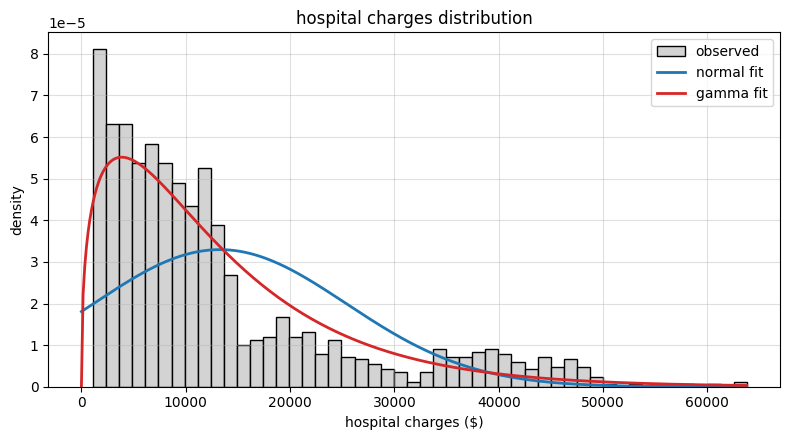

In [4]:
# 1(a)
# response = charge, and judge shape from the distrbtn (referenced from lecture 10)
y = insurance['charges']
print(f'n = {len(y)}, min = {y.min():.0f}, median = {y.median():.0f}, mean = {y.mean():.0f}, '
      f'max = {y.max():.0f}, skew = {y.skew():.2f}')
print(insurance.groupby('smoker')['charges'].agg(['mean', 'std']).round(0))

mu, sd = stats.norm.fit(y)
a, loc, scale = stats.gamma.fit(y, floc=0)
print(f'normal fit: P(charges < 0) = {stats.norm.cdf(0, mu, sd):.3f}')
print(f'gamma fit: shape = {a:.2f}, scale = {scale:.0f}')

x = np.linspace(0, y.max(), 400)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(y, bins=50, density=True, color='lightgray', edgecolor='k', lw=0.3, label='observed')
ax.plot(x, stats.norm.pdf(x, mu, sd), 'tab:blue', lw=2, label='normal fit')
ax.plot(x, stats.gamma.pdf(x, a, loc, scale), 'tab:red', lw=2, label='gamma fit')
ax.set_xlabel('hospital charges ($)')
ax.set_ylabel('density')
ax.set_title('hospital charges distribution')
ax.grid(True, alpha=0.4)
ax.legend()
fig.tight_layout()
fig.savefig(f'{RESULTS}/p1a_charges_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

hospital charges follow a gamma distribution. charges are continuous and always positive and are right-skewed (skew = 1.52, mean > median). the gamma fit only allows positive values and follows the peak and long right tail. the spread also grows with  mean (which gamma allows but normal does not because of const variance).

OLS: predicted range = -1856 to 41458, predictions < 0: 16
gamma GLM (log link functn): predicted range = 3463 to 71883, predictions < 0: 0


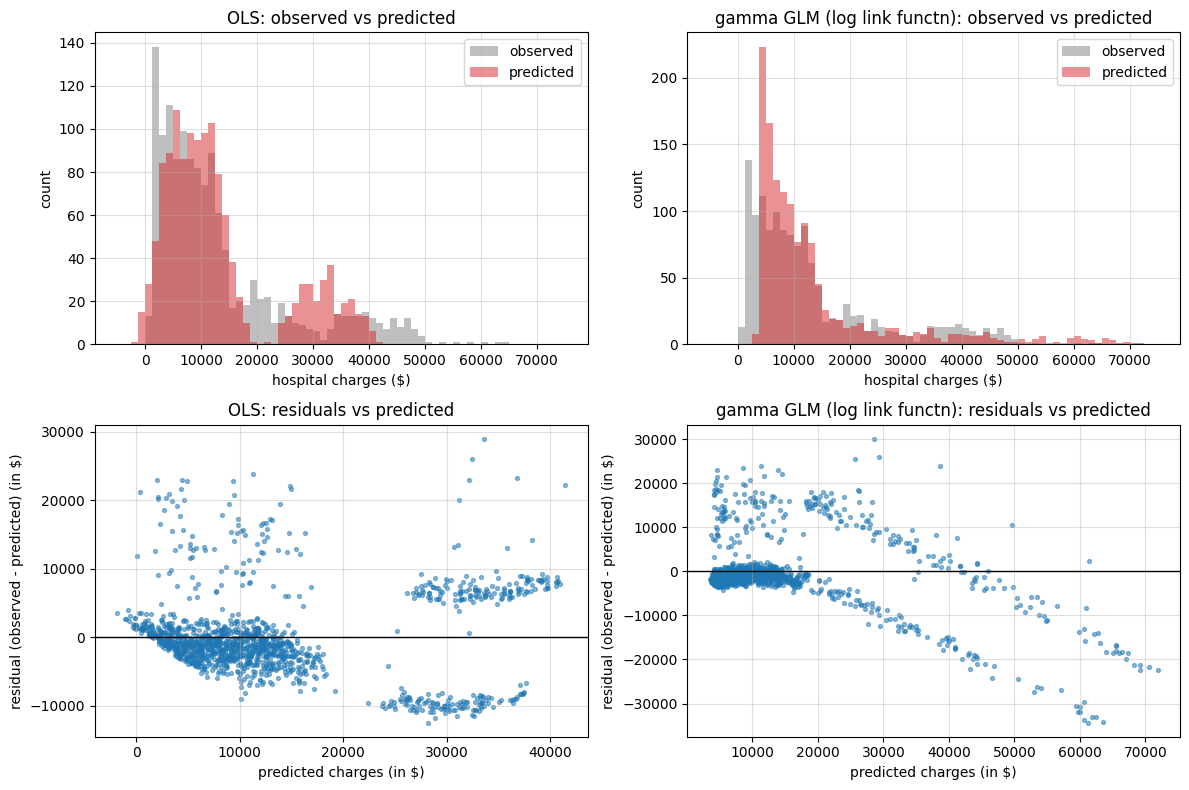

In [5]:
# 1(b)
# predictors = age, bmi, smoker, ols vs gamma glm with log link function for +ive predictions
import statsmodels.api as sm
import statsmodels.formula.api as smf

ols = smf.ols('charges ~ age + bmi + smoker', data=insurance).fit()
glm = smf.glm('charges ~ age + bmi + smoker', data=insurance,
              family=sm.families.Gamma(link=sm.families.links.Log())).fit()

models = {'OLS': ols.fittedvalues, 'gamma GLM (log link functn)': glm.fittedvalues}
for name, pred in models.items():
    print(f'{name}: predicted range = {pred.min():.0f} to {pred.max():.0f}, predictions < 0: {(pred < 0).sum()}')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
bins = np.linspace(-5000, 75000, 65)
for col, (name, pred) in enumerate(models.items()):
    ax = axes[0, col]
    ax.hist(insurance['charges'], bins=bins, alpha=0.5, color='gray', label='observed')
    ax.hist(pred, bins=bins, alpha=0.5, color='tab:red', label='predicted')
    ax.set_xlabel('hospital charges ($)')
    ax.set_ylabel('count')
    ax.set_title(f'{name}: observed vs predicted')
    ax.legend()

    ax = axes[1, col]
    ax.scatter(pred, insurance['charges'] - pred, s=8, alpha=0.5)
    ax.axhline(0, color='k', lw=1)
    ax.set_xlabel('predicted charges (in $)')
    ax.set_ylabel('residual (observed - predicted) (in $)')
    ax.set_title(f'{name}: residuals vs predicted')
for ax in axes.ravel():
    ax.grid(True, alpha=0.4)
fig.tight_layout()
fig.savefig(f'{RESULTS}/p1b_ols_vs_glm.png', dpi=200, bbox_inches='tight')
plt.show()

gamma GLM using log link functn vs OLS (predictors = age, BMI and smoker). OLS predicts 16 negative charges and a bimodal distribution that misses the long right tail, and its residuals split into separate smoker bands. GLM matches the right skewed shape with no negative predictions, but its residuals spread out as predictions grow and it over predicts the most expensive patients (71,883 vs anobserved of 63,770)

In [6]:
# 1(c)
# MAE and RMSEfor each model
smoker = insurance['smoker'] == 'yes' # MAE split by smoker/not to see where error origin
for name, pred in models.items():
    err = insurance['charges'] - pred
    print(f'{name}: MAE = {err.abs().mean():.0f}, RMSE = {np.sqrt((err**2).mean()):.0f} | '
          f'MAE smokers = {err[smoker].abs().mean():.0f}, non-smoker = {err[~smoker].abs().mean():.0f}')

OLS: MAE = 4217, RMSE = 6083 | MAE smokers = 8567, non-smoker = 3097
gamma GLM (log link functn): MAE = 4315, RMSE = 7444 | MAE smokers = 11115, non-smoker = 2564


In [7]:
np.exp(glm.params)

,0
Intercept,1710.588360
smoker[T.yes],4.351743
age,1.028834
bmi,1.012205


OLS does a better job at predicting charges because of lower MAE and RMSE.

the GLM is better for non-smokers (MAE 2,564 vs 3,097) but worse for smokers (MAE 11,115 vs 8,567). using the log link function the effects multiply because being a smoker multiplies the charge by 4.35, and that gets multiplied again by the age and BMI effects. so older and heavier smokers get predicted way too high. RMSE squares the errors, so these misses push the GLM's RMSE up a lot more than its MAE. but OLS adds the same flat amount for smoking and is fit to make the squared dollar error as small as possible (exactly what MAE and RMSE measure). therefore, GLM matches the shape of the charges better (from 1b), but OLS gives closer predictions

## Problem 2

In [9]:
sleep = pd.read_csv(f'{DATA}/sleepstudy.csv')
print(sleep.shape, f'{sleep["Subject"].nunique()} participants, days {sleep["Days"].min()}-{sleep["Days"].max()}')

(180, 4) 18 participants, days 0-9


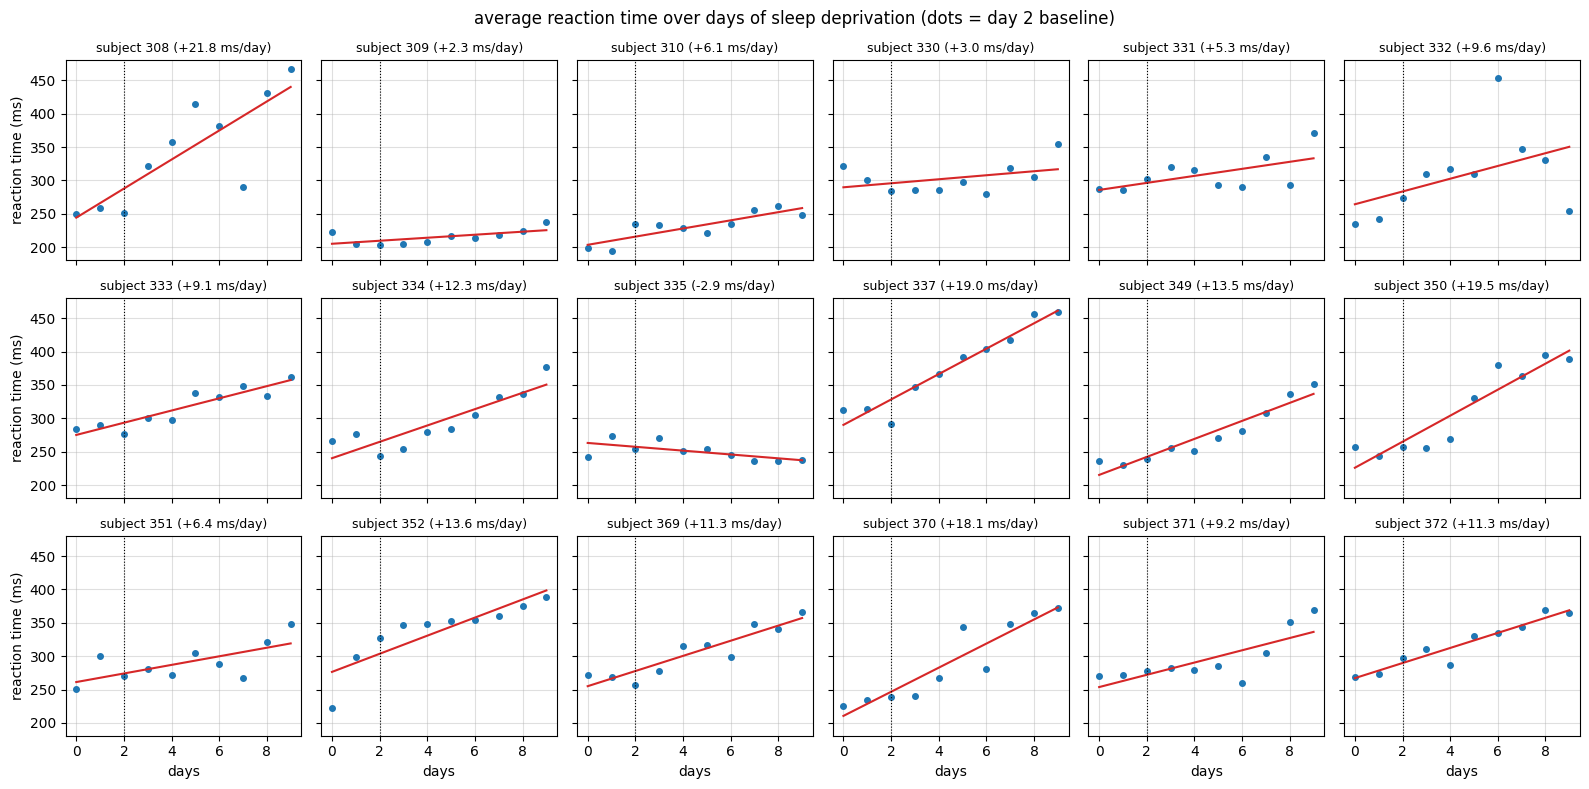

In [11]:
# 2(a)
# avg reaction time over days per participant with a linear
# reg line
# days 0-1 = training, 2 = baseline, sleep deprivation from day 2
subjects = sorted(sleep['Subject'].unique())
fig, axes = plt.subplots(3, 6, figsize=(16, 8), sharex=True, sharey=True)
for ax, s in zip(axes.ravel(), subjects):
    d = sleep[sleep['Subject'] == s]
    slope, intercept = np.polyfit(d['Days'], d['Reaction'], 1)
    ax.plot(d['Days'], d['Reaction'], 'o', ms=4)
    ax.plot(d['Days'], intercept + slope*d['Days'], 'tab:red', lw=1.5)
    ax.axvline(2, color='k', ls=':', lw=0.8)  # baseline day
    ax.set_title(f'subject {s} ({slope:+.1f} ms/day)', fontsize=9)
    ax.grid(True, alpha=0.4)
for ax in axes[-1]:
    ax.set_xlabel('days')
for ax in axes[:, 0]:
    ax.set_ylabel('reaction time (ms)')
fig.suptitle('average reaction time over days of sleep deprivation (dots = day 2 baseline)')
fig.tight_layout()
fig.savefig(f'{RESULTS}/p2a_reaction_by_subject.png', dpi=200, bbox_inches='tight')
plt.show()

each panel is one participant avg reaction time over days with a  linear reg line. slope = ms avg change in reaction time per day.

In [12]:
# 2(b)
# days 2-9
# t = days since day 2 baseline
# intercept = baseline reaction time, slope = ms added per day of deprivation
import statsmodels.formula.api as smf

dep = sleep[sleep['Days'] >= 2].assign(t=lambda d: d['Days'] - 2)
g = dep['Subject']

fits = {
    'OLS':                      (smf.ols('Reaction ~ t', data=dep).fit(), 3),
    'random intercept':         (smf.mixedlm('Reaction ~ t', dep, groups=g).fit(reml=False), 4),
    'random slope':             (smf.mixedlm('Reaction ~ t', dep, groups=g, re_formula='0 + t').fit(reml=False), 4),
    'random intercept + slope': (smf.mixedlm('Reaction ~ t', dep, groups=g, re_formula='~t').fit(reml=False), 6),
}

rows = []
for name, (m, k) in fits.items():
    re_sd = {} if name == 'OLS' else dict(zip(m.cov_re.index, np.sqrt(np.diag(m.cov_re))))
    rows.append({'model': name, 'logLik': m.llf, 'AIC': 2*k - 2*m.llf,
                 'SD intercept': re_sd.get('Group', 0), 'SD slope': re_sd.get('t', 0),
                 'SD residual': np.sqrt(m.scale)})
print(pd.DataFrame(rows).set_index('model').round(1).to_string())

ris = fits['random intercept + slope'][0]
print(f"\nfixed effects (equal for all models): baseline = {ris.params['Intercept']:.1f} ms, "
      f"slope = {ris.params['t']:.1f} ms/day")

# does adding a random intercept and  a random slope improve fit?
for a, b, df in [('OLS', 'random intercept', 1), ('random intercept', 'random intercept + slope', 2)]:
    lr = 2*(fits[b][0].llf - fits[a][0].llf)
    print(f'{a} -> {b}: LR = {lr:.1f}, p = {stats.chi2.sf(lr, df):.1e}')

# per participant own baseline and slope from the random intercept + slope (referenced BLUPs from lecture 10)
blup = pd.DataFrame(ris.random_effects).T
base = ris.params['Intercept'] + blup['Group']
slope = ris.params['t'] + blup['t']
print(f'per participant: baseline {base.min():.0f} to {base.max():.0f} ms, slope {slope.min():.1f} to {slope.max():.1f} ms/day')

                          logLik     AIC  SD intercept  SD slope  SD residual
model                                                                        
OLS                       -769.1  1544.2           0.0       0.0         50.9
random intercept          -719.2  1446.5          40.6       0.0         30.1
random slope              -722.5  1452.9           0.0       9.5         30.9
random intercept + slope  -706.6  1425.2          29.8       6.5         25.5

fixed effects (equal for all models): baseline = 268.0 ms, slope = 11.4 ms/day
OLS -> random intercept: LR = 99.7, p = 1.8e-23
random intercept -> random intercept + slope: LR = 25.3, p = 3.2e-06
per participant: baseline 209 to 314 ms, slope -0.4 to 21.6 ms/day


random intercept + slope fits best because all 4 models give the same average line and differ only in how much each participant is allowed to move away from it.

do participants differ in baseline reaction time? **YES**. Adding a random intercept to OLS improves the fit a lot (p = 1.8e-23)


do participants differ in how fast reaction time gets worse? **YES**. Adding a random slope on top of the random intercept still improves the fit (p = 3.2e-06)

## Problem 3

In [17]:
!pip install lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=6ef3978d0dc1e3a75b5c890288a24548cb3248e5d7088530e54ead55d11de7ff
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lifelines]


In [18]:
# 3(a)
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

hf = pd.read_csv(f'{DATA}/heartfailure.csv')
print(hf.shape, f'deaths = {hf["DEATH_EVENT"].sum()}, follow-up up to {hf["time"].max()} days')

(299, 13) deaths = 96, follow-up up to 285 days


EF < 35%: n = 93, deaths = 51, median survival = 170 days, S(250 days) = 0.23
EF >= 35%: n = 206, deaths = 45, median survival = not reached, S(250 days) = 0.74
log-rank test: chi2 = 30.6, p = 3.1e-08


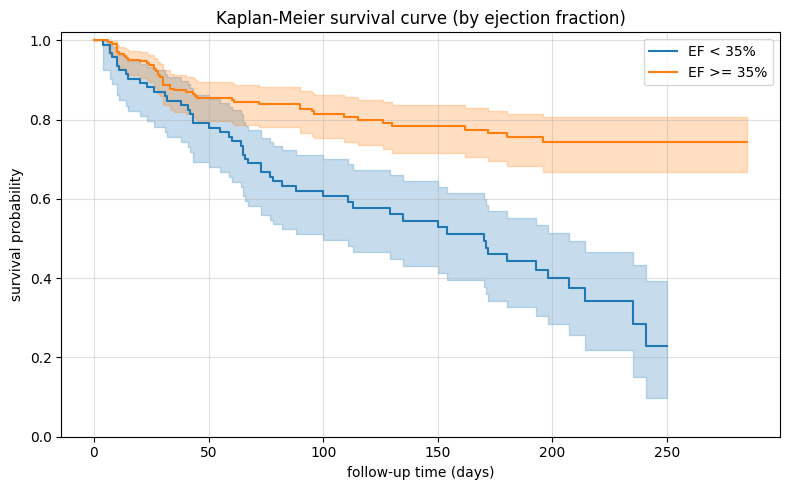

In [20]:
# Kaplan-meier curves for EF < 35% vs EF >= 35% (referenced lecture 11)
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

low_ef = hf['ejection_fraction'] < 35
fig, ax = plt.subplots(figsize=(8, 5))
for mask, label in [(low_ef, 'EF < 35%'), (~low_ef, 'EF >= 35%')]:
    km = KaplanMeierFitter(label=label).fit(hf.loc[mask, 'time'], hf.loc[mask, 'DEATH_EVENT'])
    km.plot_survival_function(ax=ax)
    med = km.median_survival_time_
    print(f'{label}: n = {mask.sum()}, deaths = {hf.loc[mask, "DEATH_EVENT"].sum()}, '
          f'median survival = {"not reached" if np.isinf(med) else f"{med:.0f} days"}, S(250 days) = {km.predict(250):.2f}')

lr = logrank_test(hf.loc[low_ef, 'time'], hf.loc[~low_ef, 'time'],
                  hf.loc[low_ef, 'DEATH_EVENT'], hf.loc[~low_ef, 'DEATH_EVENT'])
print(f'log-rank test: chi2 = {lr.test_statistic:.1f}, p = {lr.p_value:.1e}')

ax.set_xlabel('follow-up time (days)')
ax.set_ylabel('survival probability')
ax.set_title(f'Kaplan-Meier survival curve (by ejection fraction)')
ax.set_ylim(0, 1.02)
ax.grid(True, alpha=0.4)
fig.tight_layout()
fig.savefig(f'{RESULTS}/p3a_km_ejection_fraction.png', dpi=200, bbox_inches='tight')
plt.show()

patients with EF < 35% die sooner. their survival curve drops steadily. the curves overlap for the first ~40 days then split apart. patients with EF >= 35% level off around 74% survival at 250 days and never reach 50% (45 of 206 died). to compare I used the log-rank test. Intuitively makes sense that  a weaker heart pump (or low EF) means higher risk of death.

age: HR = 1.045 (95% CI 1.027-1.064), p = 8.1e-07
serum_creatinine: HR = 1.430 (95% CI 1.251-1.635), p = 1.6e-07
ejection_fraction: HR = 0.952 (95% CI 0.933-0.971), p = 1.6e-06

held at median: age = 60 yr, serum creatinine = 1.1 mg/dL
S(250 days): EF 25% = 0.47, EF 40% = 0.69, EF 55% = 0.84


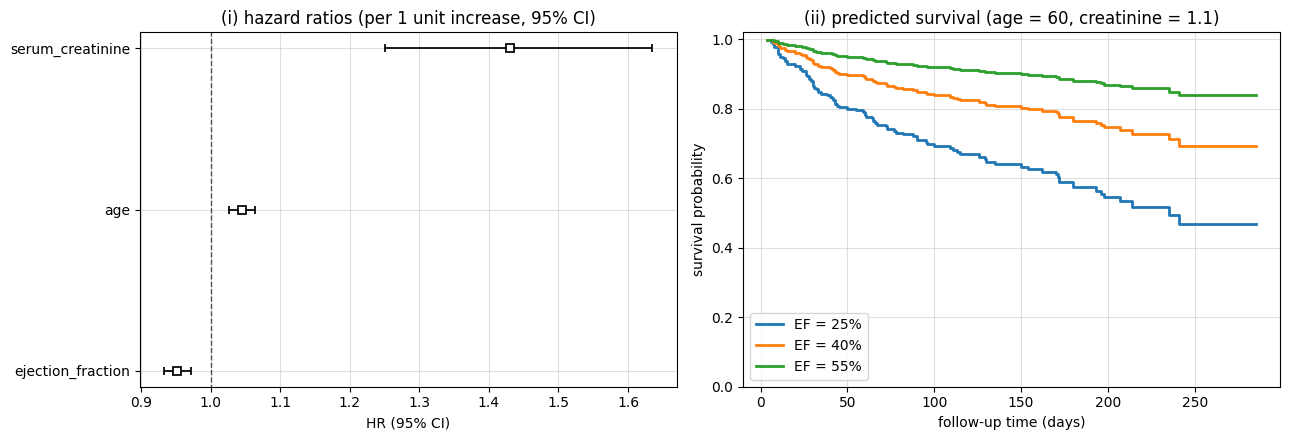

In [21]:
# 3(b)
# cox proportional hazards regression (predictors = age, serum creatinine, EF)
from lifelines import CoxPHFitter

cox_cols = ['age', 'serum_creatinine', 'ejection_fraction']
cph = CoxPHFitter().fit(hf[cox_cols + ['time', 'DEATH_EVENT']], duration_col='time', event_col='DEATH_EVENT')
for c, r in cph.summary.iterrows():
    print(f"{c}: HR = {r['exp(coef)']:.3f} (95% CI {r['exp(coef) lower 95%']:.3f}-{r['exp(coef) upper 95%']:.3f}), p = {r['p']:.1e}")

# EF = 25, 40, 55 (age and creatinine constant at their medians)
med = hf[['age', 'serum_creatinine']].median()
print(f"\nheld at median: age = {med['age']:.0f} yr, serum creatinine = {med['serum_creatinine']:.1f} mg/dL")
new_pts = pd.DataFrame({'age': med['age'], 'serum_creatinine': med['serum_creatinine'],
                        'ejection_fraction': [25, 40, 55]})
surv = cph.predict_survival_function(new_pts)
print('S(250 days):', ', '.join(f'EF {ef}% = {s:.2f}' for ef, s in zip(new_pts['ejection_fraction'], surv.iloc[-1])))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cph.plot(hazard_ratios=True, ax=axes[0])
axes[0].set_title('(i) hazard ratios (per 1 unit increase, 95% CI)')
axes[0].grid(True, alpha=0.4)

for col, ef in zip(surv.columns, new_pts['ejection_fraction']):
    axes[1].step(surv.index, surv[col], where='post', lw=2, label=f'EF = {ef}%')
axes[1].set_xlabel('follow-up time (days)')
axes[1].set_ylabel('survival probability')
axes[1].set_title(f"(ii) predicted survival (age = {med['age']:.0f}, creatinine = {med['serum_creatinine']:.1f})")
axes[1].set_ylim(0, 1.02)
axes[1].grid(True, alpha=0.4)
axes[1].legend()
fig.tight_layout()
fig.savefig(f'{RESULTS}/p3b_cox.png', dpi=200, bbox_inches='tight')
plt.show()

cox model on age, serum creatinine and EF

HR > 1 means higher risk of death because each extra year of age and each extra of creatinine raise risk, each extra % of EF lowers it, and all 3 CIs stay off 1. Holding age and creatinine const at their medians, predicted survival at 250 days goes 47% (EF 25) to 69%(EF 40) to 84%(EF 55)

In [22]:
# 3(c)
# hazard ratios (step size k = exp(k * coef))
steps = {'age': (10, '10 yr'), 'serum_creatinine': (0.5, '0.5 mg/dL'), 'ejection_fraction': (10, '10%')}
for c, (k, label) in steps.items():
    r = cph.summary.loc[c]
    lo, hi = np.exp(k * r['coef lower 95%']), np.exp(k * r['coef upper 95%'])
    print(f'{c} +{label}: HR = {np.exp(k * r["coef"]):.2f} (95% CI {lo:.2f}-{hi:.2f})')

age +10 yr: HR = 1.56 (95% CI 1.31-1.85)
serum_creatinine +0.5 mg/dL: HR = 1.20 (95% CI 1.12-1.28)
ejection_fraction +10%: HR = 0.61 (95% CI 0.50-0.75)


## Problem 4

In [23]:
spine = pd.read_csv(f'{DATA}/vertebralcolumn.csv')
print(spine.shape, spine['class'].value_counts().to_dict())

(310, 7) {'Spondylolisthesis': 150, 'Normal': 100, 'Hernia': 60}


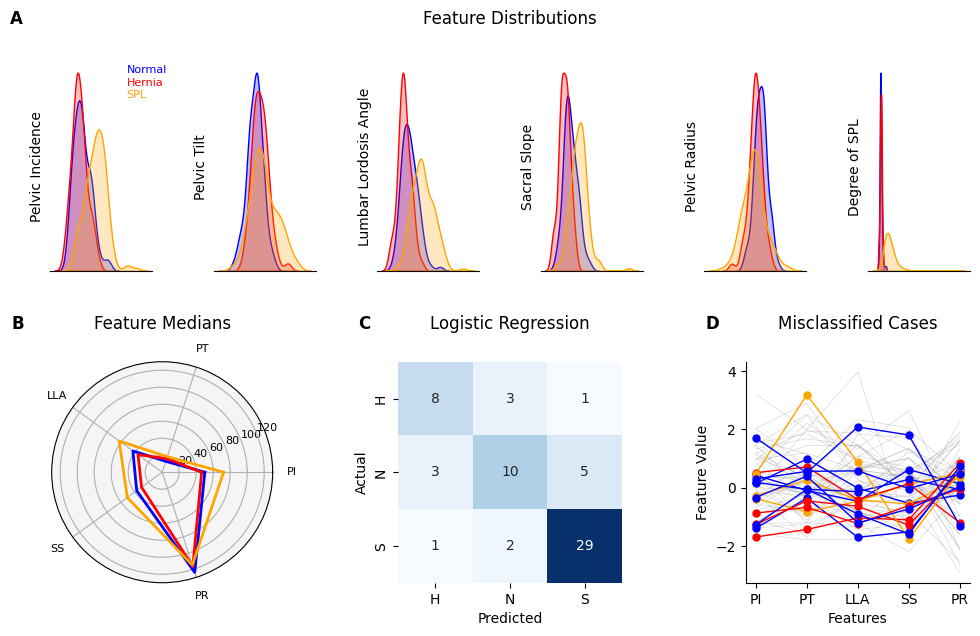

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

FEATS = ['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle', 'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis']
NAMES = ['Pelvic Incidence', 'Pelvic Tilt', 'Lumbar Lordosis Angle', 'Sacral Slope', 'Pelvic Radius', 'Degree of SPL']
# onlu 5 shape features
SHORT = ['PI', 'PT', 'LLA', 'SS', 'PR']
CLASSES = {'Normal': 'blue', 'Hernia': 'red', 'Spondylolisthesis': 'orange'}

fig = plt.figure(figsize=(10, 6.5))
top = fig.add_gridspec(1, 6, left=0.06, right=0.98, top=0.88, bottom=0.56, wspace=0.6)
bot = fig.add_gridspec(1, 3, left=0.06, right=0.98, top=0.42, bottom=0.08, wspace=0.55)

def panel(ax, letter, title, y):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.04, y, letter, fontsize=12, fontweight='bold')
    fig.text(pos.x0 + pos.width/2, y, title, fontsize=12, ha='center')

# A (scaled to their own areas)
for i, (f, name) in enumerate(zip(FEATS, NAMES)):
    ax = fig.add_subplot(top[0, i])
    for c, col in CLASSES.items():
        sns.kdeplot(spine.loc[spine['class'] == c, f], ax=ax, color=col, fill=True, alpha=0.25, lw=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(''); ax.set_ylabel(name)
    sns.despine(ax=ax, left=True)
    if i == 0:
        for k, (lbl, col) in enumerate([('Normal', 'blue'), ('Hernia', 'red'), ('SPL', 'orange')]):
            ax.text(0.75, 0.95 - 0.06*k, lbl, color=col, fontsize=8, transform=ax.transAxes)
fig.text(0.02, 0.94, 'A', fontsize=12, fontweight='bold')
fig.text(0.52, 0.94, 'Feature Distributions', fontsize=12, ha='center')

# B (class medians radar)
ax = fig.add_subplot(bot[0, 0], polar=True)
ang = np.linspace(0, 2*np.pi, len(SHORT), endpoint=False)
med = spine.groupby('class')[FEATS[:5]].median()
for c, col in CLASSES.items():
    r = med.loc[c].values
    ax.plot(np.append(ang, ang[0]), np.append(r, r[0]), color=col, lw=2)
ax.set_xticks(ang)
ax.set_xticklabels(SHORT, fontsize=8)
ax.set_yticks([20, 40, 60, 80, 100, 120])
ax.set_ylim(0, 130)
ax.tick_params(axis='y', labelsize=8)
ax.set_facecolor('whitesmoke')
panel(ax, 'B', 'Feature Medians', 0.47)

# C (logistic reg on the 5 features with split)
X, y = spine[FEATS[:5]], spine['class']
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
log_reg = LogisticRegression(max_iter=1000, random_state=42).fit(x_train, y_train)
pred = log_reg.predict(x_test)
# row and cols in this order hernia, normal, spl
cm = confusion_matrix(y_test, pred)
ax = fig.add_subplot(bot[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['H', 'N', 'S'], yticklabels=['H', 'N', 'S'], ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
panel(ax, 'C', 'Logistic Regression', 0.47)

# D (z scored features on test, misclassified colored by true class)
z = pd.DataFrame(StandardScaler().fit_transform(X), columns=SHORT, index=X.index).loc[x_test.index]
wrong = y_test != pred
ax = fig.add_subplot(bot[0, 2])
xpos = np.arange(len(SHORT))
for idx in z.index[~wrong]:
    ax.plot(xpos, z.loc[idx], color='gray', lw=0.5, alpha=0.3)
for idx in z.index[wrong]:
    ax.plot(xpos, z.loc[idx], 'o-', color=CLASSES[y_test[idx]], lw=1, ms=5)
ax.set_xticks(xpos)
ax.set_xticklabels(SHORT)
ax.set_xlabel('Features'); ax.set_ylabel('Feature Value')
sns.despine(ax=ax)
panel(ax, 'D', 'Misclassified Cases', 0.47)

fig.savefig(f'{RESULTS}/p4_recreated_figure.png', dpi=200, bbox_inches='tight')
plt.show()